# Land-only spin-ups after the CO₂ fix: are they in equilibrium?

**Runs (2026-10-23 → 10-24, 100 yr each, `CLM_CO2_TYPE=diagnostic`, `CCSM_BGC=CO2A`).** CLM takes the CO₂ from the cplhist forcing, as in the coupled runs.

| Label | Script | Case | Surfdata |
|---|---|---|---|
| `PD_LCC` | 12b | `I2000Clm50BgcCropCplHist_lcc_f19_f19-20261023` | LPJ-GUESS 2100 |
| `FUT_CTRL` | 22c | `I2100ssp585Clm50BgcCropCplHist_ctrl_f19_f19-20261023` | CTRL (simyr2000) |
| `FUT_LCC` | 22b | `I2100ssp585Clm50BgcCropCplHist_lcc_f19_f19-20261023` | LPJ-GUESS 2100 |

For reference (dashed lines), the **old** FUT run `FUT_LCC_old` (`I2100…-20260924`, constant 284 ppm, the CO₂ bug). It has no TWS or TOTVEGN.

**FUT_CTRL and FUT_LCC are identical outside the modified cells** (§6). FUT_CTRL is drawn last as a thin line on top of FUT_LCC, so both stay visible.

**Criterion (user, 2026-10-22).** The short-term state (TWS, H2OSOI and TSOI at 1.06 m) must be in equilibrium at hand-over (year 100). Carbon (GPP, TOTVEGC, TOTVEGN) is shown for information only.
- **Drift test:** `ratio = |OLS trend over the last 10 yr, per decade| / IAV`, where IAV = SD of the detrended last 10 annual values. Below 1, the drift over a decade is smaller than the year-to-year noise. It is descriptive, not a hard threshold.
- **Rolling derivative:** `d(y) = (X[y] − X[y−20]) / 20` of the 20-yr trailing mean, against ± IAV/20.
- **Members agree (FUT only):** FUT_LCC − FUT_CTRL over the last 10 yr, outside the modified cells, in units of FUT_CTRL's IAV. Same forcing and set-up, different surfdata only at 46–82°N, so Δ should be ≈ 0 there. PD has no CTRL land-only run.

Regions: modified cells; unmodified land (all land cells outside the modified ones); global land (= both). Weights = `area × landfrac`. Annual means weighted by `time_bounds` length.

In [1]:
import os
os.environ.setdefault('HDF5_USE_FILE_LOCKING', 'FALSE')  # before netCDF4/xarray import
from pathlib import Path
import re
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import netCDF4

# New runs: Betzy work archive first (complete), NIRD archive as fallback; old runs: NIRD archive.
ARCHIVES = [Path('/cluster/work/users/adelez/archive'), Path('/nird/datapeak/NS9188K/adelez/BRL-FRST-XPSN_archive')]
MASK_FILE = Path('../lcc-modified-cells/modified_cells.nc')
OUT = Path('check_land_only_equilibrium_after_co2_fix_outputs')
CACHE = OUT / 'cache'  # regenerable annual means; delete or set REBUILD_CACHE = True after changing inputs
CACHE.mkdir(parents=True, exist_ok=True)
REBUILD_CACHE = False

RUNS = pd.DataFrame([
    ('PD_LCC',      'PD',  'LCC',  'new', 'I2000Clm50BgcCropCplHist_lcc_f19_f19-20261023'),
    ('FUT_LCC',     'FUT', 'LCC',  'new', 'I2100ssp585Clm50BgcCropCplHist_lcc_f19_f19-20261023'),
    ('FUT_CTRL',    'FUT', 'CTRL', 'new', 'I2100ssp585Clm50BgcCropCplHist_ctrl_f19_f19-20261023'),  # after FUT_LCC: drawn on top
    ('FUT_LCC_old', 'FUT', 'LCC',  'old', 'I2100ssp585Clm50BgcCropCplHist_f19_f19-20260924'),  # CO2 bug (284 ppm)
], columns=['run', 'period', 'branch', 'version', 'case']).set_index('run')
NEW = list(RUNS.index[RUNS.version == 'new'])

VARS = ['TLAI', 'HTOP', 'TWS', 'H2OSOI_1m', 'TSOI_1m', 'GPP', 'TOTVEGC', 'TOTVEGN', 'CO2_ppm']
SOIL = {'H2OSOI_1m': 'H2OSOI', 'TSOI_1m': 'TSOI'}
SOIL_INDEX = 8  # levgrnd[8] = 1.06 m (asserted)
SHORT_TERM = ['TWS', 'H2OSOI_1m', 'TSOI_1m']
CARBON = ['GPP', 'TOTVEGC', 'TOTVEGN']
ROLL, LAST = 20, 10
COLOR = {'PD_LCC': '#4daf4a', 'FUT_CTRL': '#1f77b4', 'FUT_LCC': '#d95f02', 'FUT_LCC_old': '#d95f02'}
LW = {'FUT_CTRL': 0.5}  # thinner, so FUT_LCC shows underneath where the two are identical

## 1. Read the annual means

One cache file per run in `check_land_only_equilibrium_after_co2_fix_outputs/cache/`. Only complete years (365 days) are kept. `CO2_ppm` = `PCO2/PBOT × 10⁶` (absent in the old runs).

In [2]:
def hist_files(case):
    for root in ARCHIVES:
        files = sorted((root / case / 'lnd/hist').glob('*.clm2.h0.*.nc'))
        if files:
            return files
    raise FileNotFoundError(case)

def read_file(path):
    with netCDF4.Dataset(path) as d:
        t = d['time']
        assert t.calendar == 'noleap' and re.fullmatch(r'days since \d{4}-01-01( 00:00:00)?', t.units), (path, t.units)
        bounds = d['time_bounds'][:].astype(float)
        mid = bounds.mean(1)
        out = dict(mid=mid, year=int(t.units.split()[2][:4]) + np.floor(mid / 365).astype(int), days=bounds[:, 1] - bounds[:, 0])
        for v in VARS:
            if v in d.variables:
                out[v] = np.ma.filled(d[v][:].astype(float), np.nan)
        for new, old in SOIL.items():
            if old in d.variables:
                assert abs(float(d['levgrnd'][SOIL_INDEX]) - 1.06) < 0.01, f'{path}: soil levels changed'
                out[new] = np.ma.filled(d[old][:, SOIL_INDEX].astype(float), np.nan)
        if {'PCO2', 'PBOT'} <= set(d.variables):
            out['CO2_ppm'] = np.ma.filled((d['PCO2'][:] / d['PBOT'][:] * 1e6).astype(float), np.nan)
    return out

def annual_means(case):
    files = hist_files(case)
    parts = [read_file(f) for f in files]
    mid = np.concatenate([p['mid'] for p in parts])
    assert len(np.unique(mid)) == len(mid), f'{case}: duplicated time steps'
    year = np.concatenate([p['year'] for p in parts])
    days = np.concatenate([p['days'] for p in parts])
    keep = [y for y in np.unique(year) if abs(days[year == y].sum() - 365) < 0.5]
    with netCDF4.Dataset(files[0]) as d:
        coords = dict(lat=d['lat'][:].data, lon=d['lon'][:].data)
        grid = {v: (('lat', 'lon'), np.ma.filled(d[v][:].astype(float), np.nan)) for v in ('area', 'landfrac')}
        units = {v: d[SOIL.get(v, v)].units for v in VARS if SOIL.get(v, v) in d.variables}
    data = {}
    for v in [v for v in VARS if all(v in p for p in parts)]:
        x = np.concatenate([p[v] for p in parts])
        rows = []
        for y in keep:
            sel = year == y
            total = np.nansum(x[sel] * days[sel][:, None, None], 0)
            total[np.isnan(x[sel]).all(0)] = np.nan
            rows.append(total / days[sel].sum())
        data[v] = (('year', 'lat', 'lon'), np.stack(rows), {'units': 'ppm' if v == 'CO2_ppm' else units.get(v, '?')})
    return xr.Dataset({**data, **grid}, coords=dict(year=keep, **coords), attrs=dict(case=case, source=str(files[0].parent)))

def load_run(run):
    path = CACHE / f'annual_{run}.nc'
    if path.is_file() and not REBUILD_CACHE:
        with xr.open_dataset(path) as ds:
            return ds.load()
    ann = annual_means(RUNS.loc[run, 'case'])
    tmp = path.with_name(path.stem + '.tmp.nc')
    ann.to_netcdf(tmp)
    os.replace(tmp, path)
    return ann

ANN = {run: load_run(run) for run in RUNS.index}
ref = ANN['FUT_CTRL']
for run, a in ANN.items():
    assert np.array_equal(a.lat, ref.lat) and np.array_equal(a.lon, ref.lon), run
    assert np.allclose(a.landfrac, ref.landfrac, equal_nan=True), run
print(pd.DataFrame({r: dict(years=f"{int(a.year[0])}–{int(a.year[-1])} ({a.sizes['year']})", source=a.source,
                            vars=', '.join(v for v in VARS if v in a)) for r, a in ANN.items()}).T.to_string())

                   years                                                                                            source                                                                 vars
PD_LCC       1–100 (100)         /cluster/work/users/adelez/archive/I2000Clm50BgcCropCplHist_lcc_f19_f19-20261023/lnd/hist  TLAI, HTOP, TWS, H2OSOI_1m, TSOI_1m, GPP, TOTVEGC, TOTVEGN, CO2_ppm
FUT_LCC      1–100 (100)   /cluster/work/users/adelez/archive/I2100ssp585Clm50BgcCropCplHist_lcc_f19_f19-20261023/lnd/hist  TLAI, HTOP, TWS, H2OSOI_1m, TSOI_1m, GPP, TOTVEGC, TOTVEGN, CO2_ppm
FUT_CTRL     1–100 (100)  /cluster/work/users/adelez/archive/I2100ssp585Clm50BgcCropCplHist_ctrl_f19_f19-20261023/lnd/hist  TLAI, HTOP, TWS, H2OSOI_1m, TSOI_1m, GPP, TOTVEGC, TOTVEGN, CO2_ppm
FUT_LCC_old  1–100 (100)       /cluster/work/users/adelez/archive/I2100ssp585Clm50BgcCropCplHist_f19_f19-20260924/lnd/hist                               TLAI, H2OSOI_1m, TSOI_1m, GPP, TOTVEGC


In [3]:
mask = xr.open_dataset(MASK_FILE).modified.astype(bool)
assert np.allclose(mask.lat, ref.lat) and np.allclose(mask.lon, ref.lon)
mask = mask.assign_coords(lat=ref.lat, lon=ref.lon)
LAND = ref.landfrac > 0
REGIONS = {
    'modified cells': LAND & mask,
    'unmodified land': LAND & ~mask,
    'global land': LAND,
}
W = ref.area * ref.landfrac

def regional_mean(field, region):
    w = W.where(REGIONS[region] & np.isfinite(field))
    return (field * w).sum(('lat', 'lon')) / w.sum(('lat', 'lon'))

def per_year(v, field):
    return field * 86400 * 365 if v == 'GPP' else field

def units_of(v):
    return 'gC/m^2/yr' if v == 'GPP' else next(ANN[r][v].attrs['units'] for r in RUNS.index if v in ANN[r])

SERIES = {(run, r, v): regional_mean(per_year(v, ANN[run][v]), r)
          for run in RUNS.index for r in REGIONS for v in VARS if v in ANN[run]}

## 2. CO₂ seen by CLM

Global land median of the annual `PCO2/PBOT × 10⁶`, first and last year. Expected: ≈370 ppm (PD) and ≈1134–1142 ppm (FUT), as in the coupled runs.

In [4]:
co2 = pd.DataFrame({run: dict(first_year=float(np.nanmedian(ANN[run].CO2_ppm.isel(year=0).where(LAND))),
                              last_year=float(np.nanmedian(ANN[run].CO2_ppm.isel(year=-1).where(LAND))))
                    for run in NEW}).T.round(1)
co2.to_csv(OUT / 'co2_seen.csv')
co2

,first_year,last_year
PD_LCC,369.1,369.1
FUT_LCC,1135.2,1135.2
FUT_CTRL,1135.2,1135.2


## 3. Time series

Thin lines: annual means; thick lines: 20-yr trailing mean. Solid lines are the new runs, dashed lines the old ones (for reference only).

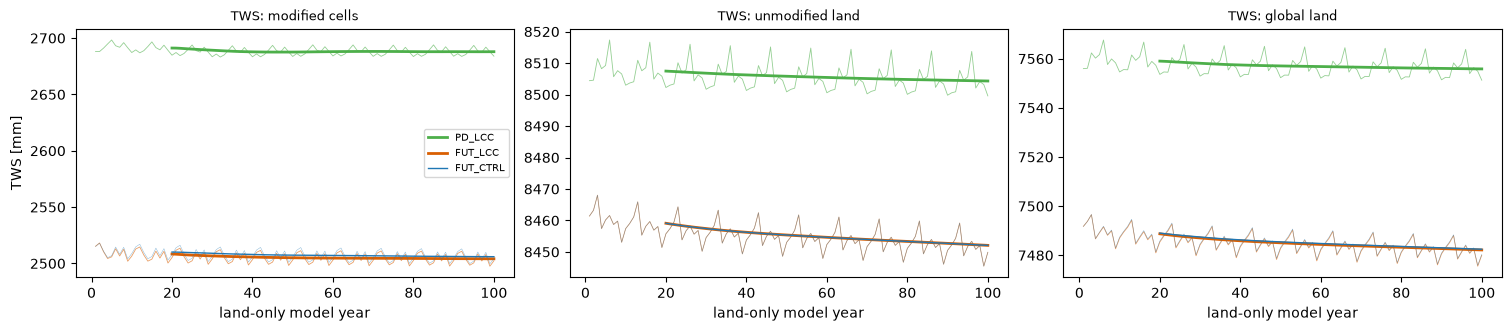

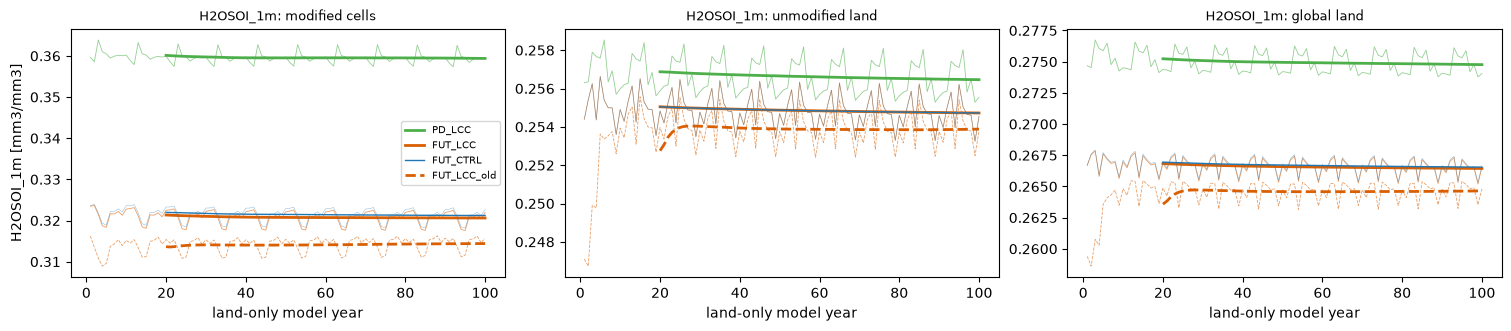

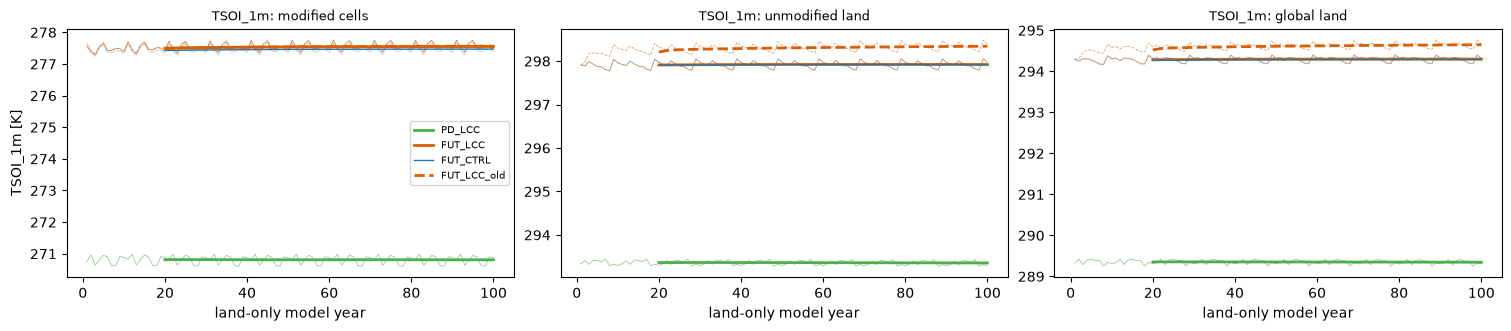

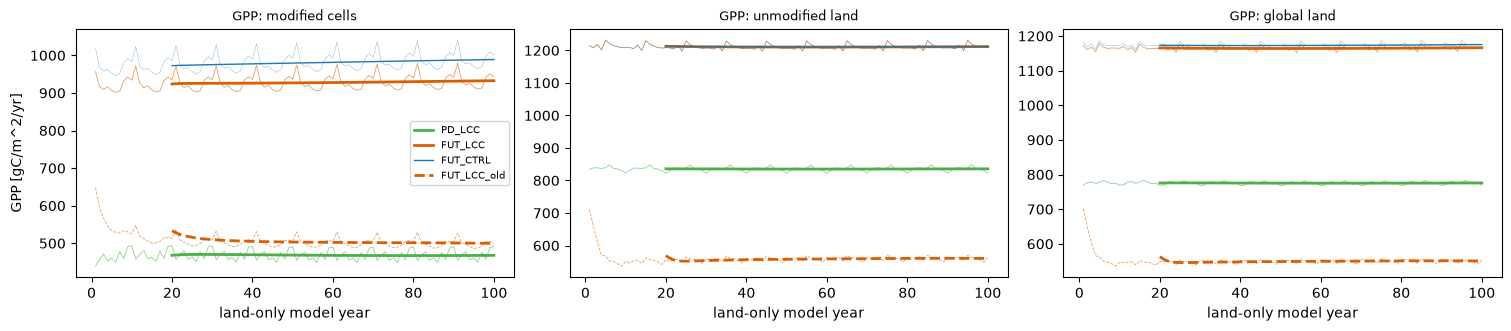

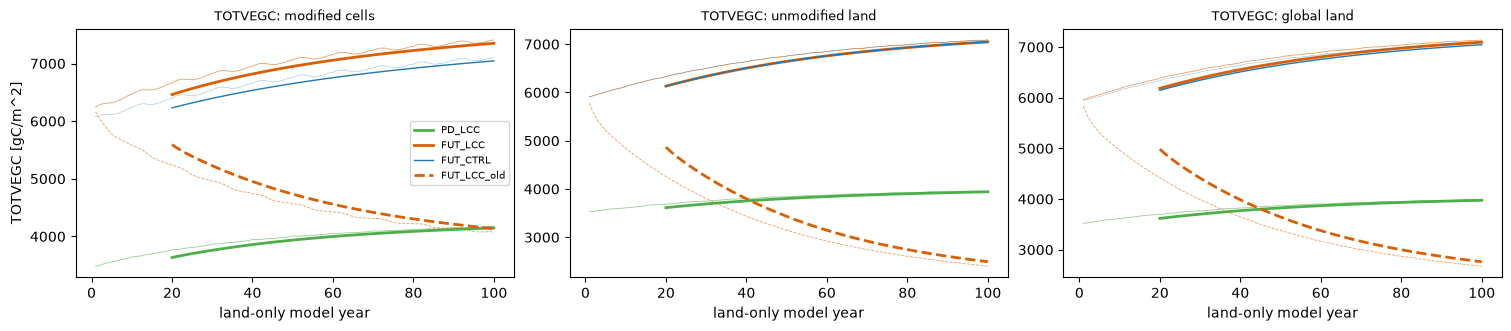

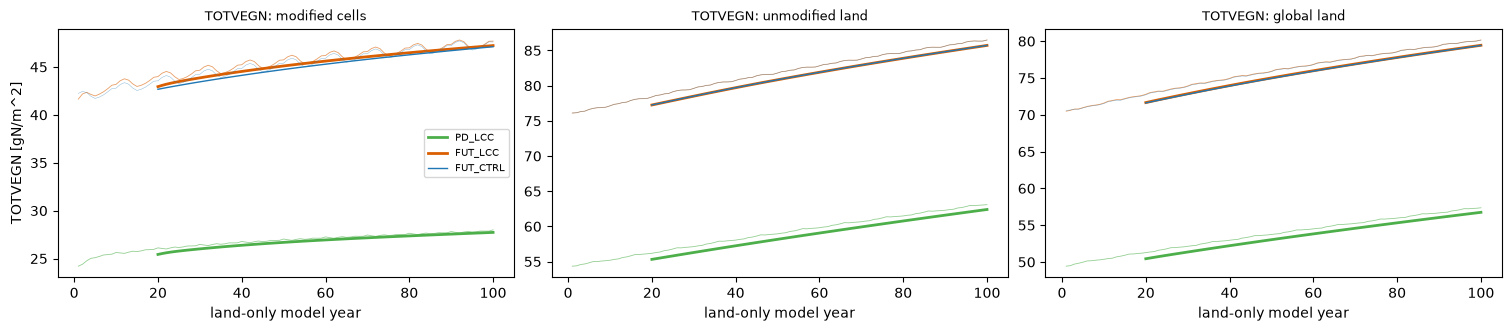

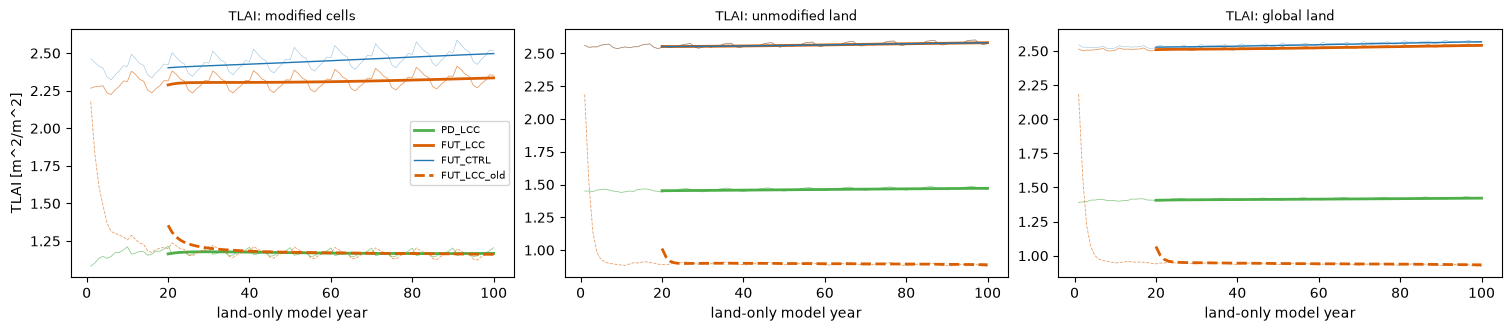

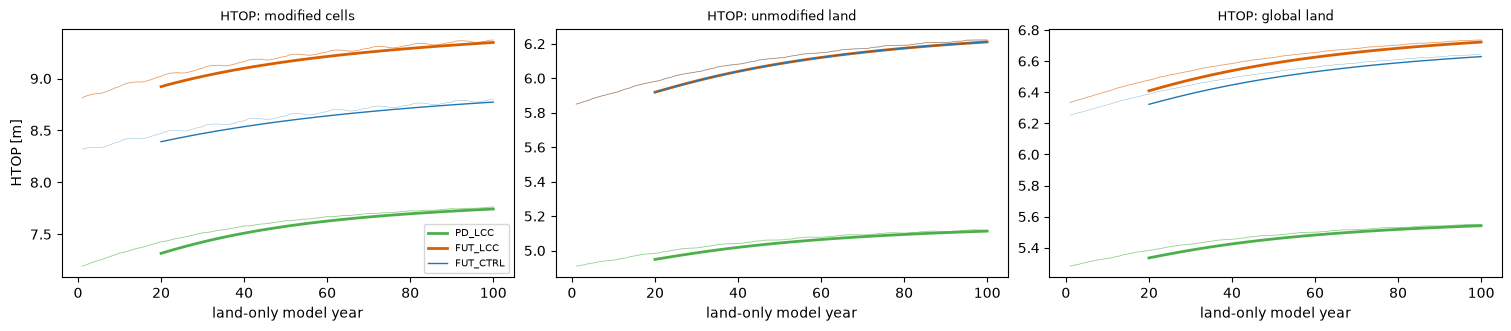

In [5]:
def series_figure(v):
    fig, axes = plt.subplots(1, len(REGIONS), figsize=(5 * len(REGIONS), 3.2), layout='constrained')
    for ax, region in zip(axes, REGIONS):
        for run, s in RUNS.iterrows():
            if (run, region, v) not in SERIES:
                continue
            y = SERIES[run, region, v]
            ls = '-' if s.version == 'new' else '--'
            ax.plot(y.year, y, color=COLOR[run], lw=0.6 * LW.get(run, 1), ls=ls, alpha=0.6)
            ax.plot(y.year, y.rolling(year=ROLL).mean(), color=COLOR[run], lw=2 * LW.get(run, 1), ls=ls, label=run)
        ax.set_title(f'{v}: {region}', fontsize=9)
        ax.set_xlabel('land-only model year')
    axes[0].set_ylabel(f'{v} [{units_of(v)}]')
    axes[0].legend(fontsize=7)
    fig.savefig(OUT / f'fig_series_{v}.png', dpi=150)
    plt.show()

for v in SHORT_TERM + CARBON + ['TLAI', 'HTOP']:
    series_figure(v)

## 4. Derivative of the 20-yr rolling mean (new runs)

Dotted lines: ± IAV / 20 yr, where IAV is the SD of the detrended last 20 annual values. A derivative inside the band means the 20-yr mean changes by less than one year of noise per year.

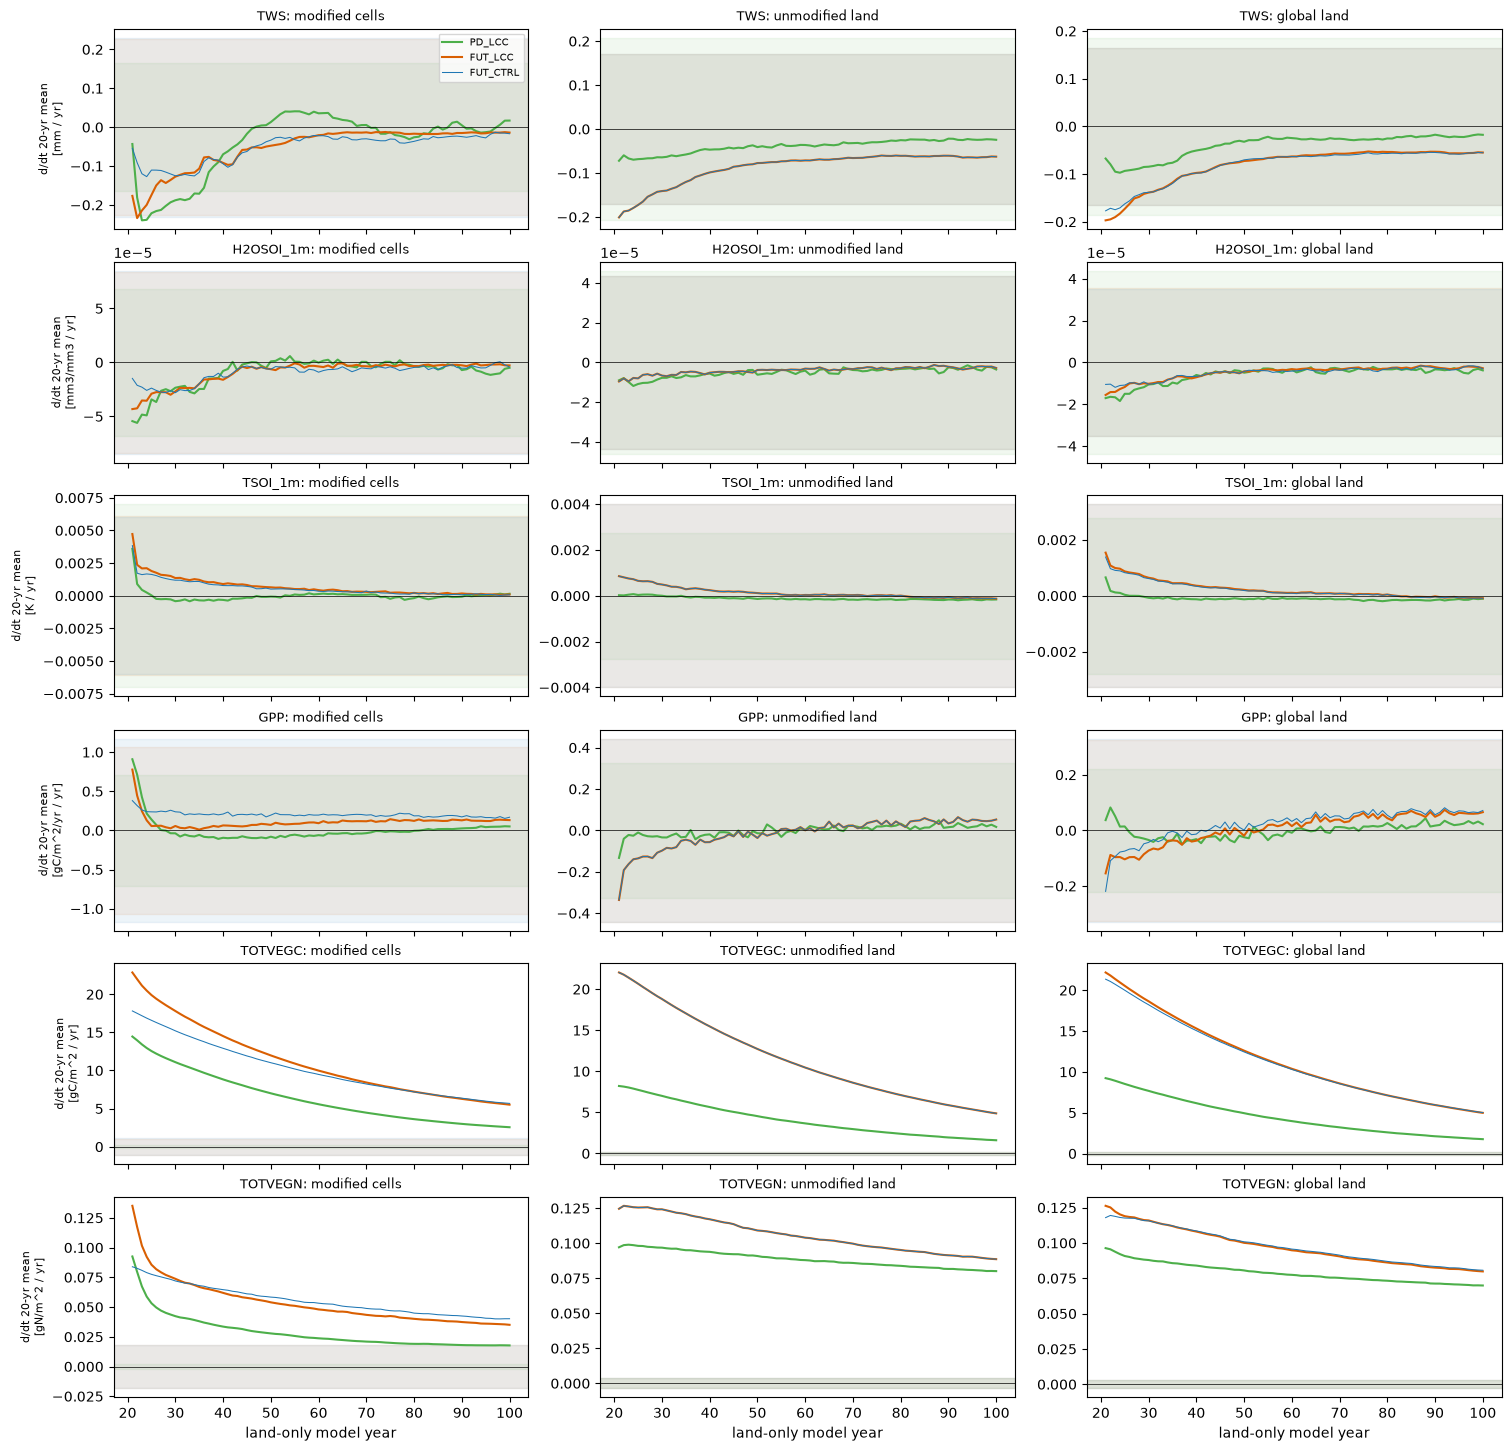

In [6]:
def detrended_sd(y):
    x = y.year.values.astype(float)
    return float(np.std(y.values - np.polyval(np.polyfit(x, y.values, 1), x), ddof=2))

fig, axes = plt.subplots(len(SHORT_TERM + CARBON), len(REGIONS), figsize=(5 * len(REGIONS), 2.4 * len(SHORT_TERM + CARBON)),
                         sharex=True, layout='constrained')
for i, v in enumerate(SHORT_TERM + CARBON):
    for j, region in enumerate(REGIONS):
        ax = axes[i, j]
        for run in NEW:
            y = SERIES[run, region, v]
            d = y.rolling(year=ROLL).mean().diff('year')
            ax.plot(d.year, d, color=COLOR[run], lw=1.5 * LW.get(run, 1), label=run)
            band = detrended_sd(y.isel(year=slice(-ROLL, None))) / ROLL
            ax.axhspan(-band, band, color=COLOR[run], alpha=0.08)
        ax.axhline(0, color='k', lw=0.5)
        ax.set_title(f'{v}: {region}', fontsize=9)
        if j == 0:
            ax.set_ylabel(f'd/dt {ROLL}-yr mean\n[{units_of(v)} / yr]', fontsize=8)
axes[0, 0].legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel('land-only model year')
fig.savefig(OUT / 'fig_rolling_derivative.png', dpi=150)
plt.show()

## 5. Verdict: cycle-to-cycle drift (main test)

**The forcing repeats every 10 years.** `DATM_CPLHIST_YR_START/END = 11/20` in all three cases: the datm loops years 11–20 of the coupled spin-up (a, `xmlquery`). Year *y* and year *y − 10* therefore see identical forcing, so `X[y] − X[y−10]` contains only the land's own drift.
- **drift per cycle** = mean(years 91–100) − mean(years 81–90).
- **ratio_cycle** = |drift per cycle| / IAV, where IAV = SD of the 10 annual values of the last cycle. That SD is variability forced by the 10 different forcing years.
- Below 1, one more decade of spin-up changes the state by less than the year-to-year spread the forcing produces. Short-term variables carry the flag `in_equilibrium` (ratio_cycle < 1).

In [7]:
CYCLE = 10
rows = []
for run in NEW:
    for region in REGIONS:
        for v in SHORT_TERM + CARBON:
            y = SERIES[run, region, v]
            last, prev = y.isel(year=slice(-CYCLE, None)), y.isel(year=slice(-2 * CYCLE, -CYCLE))
            drift = float(last.mean() - prev.mean())
            iav = float(last.std(ddof=1))
            rows.append(dict(run=run, region=region, variable=v, units=units_of(v), mean=float(last.mean()),
                             drift_per_cycle=drift, iav_sd=iav, ratio_cycle=abs(drift) / iav,
                             drift_pct_per_cycle=100 * drift / float(last.mean())))
cycle = pd.DataFrame(rows)
cycle['in_equilibrium'] = cycle.ratio_cycle < 1
cycle.to_csv(OUT / 'verdict_cycle_drift.csv', index=False)

short_c = cycle[cycle.variable.isin(SHORT_TERM)]
print('SHORT-TERM: |mean(91-100) - mean(81-90)| / IAV   (< 1 = in equilibrium)')
display(short_c.pivot_table(index=['variable', 'region'], columns='run', values='ratio_cycle')[NEW].round(2))
print('SHORT-TERM: drift per cycle (native units)')
display(short_c.pivot_table(index=['variable', 'region', 'units'], columns='run', values='drift_per_cycle')[NEW].round(4))
print('CARBON (information only): drift per cycle, %')
display(cycle[cycle.variable.isin(CARBON)].pivot_table(index=['variable', 'region'], columns='run',
                                                       values='drift_pct_per_cycle')[NEW].round(2))
print(f"Short-term cases with ratio_cycle >= 1: {int((~short_c.in_equilibrium).sum())} of {len(short_c)}")

SHORT-TERM: |mean(91-100) - mean(81-90)| / IAV   (< 1 = in equilibrium)


run                        PD_LCC  FUT_LCC  FUT_CTRL
variable  region                                    
H2OSOI_1m global land        0.04     0.04      0.04
          modified cells     0.08     0.01      0.00
          unmodified land    0.02     0.04      0.04
TSOI_1m   global land        0.02     0.01      0.01
          modified cells     0.01     0.01      0.00
          unmodified land    0.03     0.01      0.01
TWS       global land        0.06     0.15      0.16
          modified cells     0.07     0.02      0.04
          unmodified land    0.05     0.17      0.17

SHORT-TERM: drift per cycle (native units)


run                                PD_LCC  FUT_LCC  FUT_CTRL
variable  region          units                             
H2OSOI_1m global land     mm3/mm3 -0.0000  -0.0000   -0.0000
          modified cells  mm3/mm3 -0.0001  -0.0000   -0.0000
          unmodified land mm3/mm3 -0.0000  -0.0000   -0.0000
TSOI_1m   global land     K       -0.0013  -0.0007   -0.0008
          modified cells  K        0.0010   0.0009    0.0006
          unmodified land K       -0.0018  -0.0011   -0.0011
TWS       global land     mm      -0.2222  -0.5337   -0.5472
          modified cells  mm      -0.2387  -0.0942   -0.1766
          unmodified land mm      -0.2190  -0.6193   -0.6194

CARBON (information only): drift per cycle, %


run                       PD_LCC  FUT_LCC  FUT_CTRL
variable region                                    
GPP      global land        0.03     0.06      0.06
         modified cells     0.12     0.14      0.17
         unmodified land    0.02     0.04      0.04
TOTVEGC  global land        0.43     0.69      0.70
         modified cells     0.61     0.74      0.80
         unmodified land    0.40     0.68      0.68
TOTVEGN  global land        1.22     1.00      1.01
         modified cells     0.63     0.74      0.84
         unmodified land    1.27     1.03      1.03

Short-term cases with ratio_cycle >= 1: 0 of 27


### Cycle means over the whole run

Mean of each 10-yr forcing cycle (1–10, 11–20, …, 91–100) for the short-term variables. The cycle means of a run in equilibrium are flat.

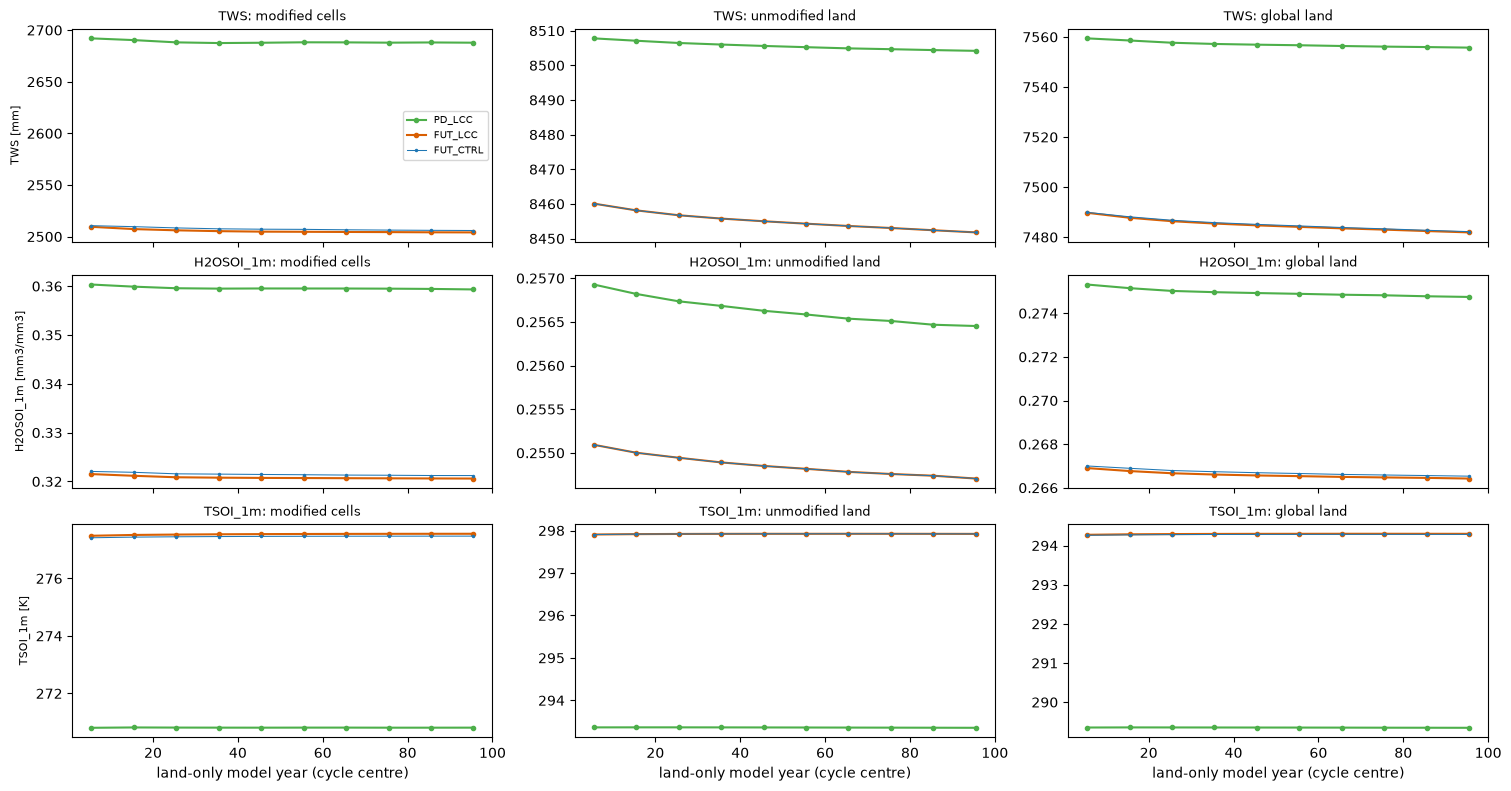

In [8]:
fig, axes = plt.subplots(len(SHORT_TERM), len(REGIONS), figsize=(5 * len(REGIONS), 2.6 * len(SHORT_TERM)),
                         sharex=True, layout='constrained')
for i, v in enumerate(SHORT_TERM):
    for j, region in enumerate(REGIONS):
        ax = axes[i, j]
        for run in NEW:
            y = SERIES[run, region, v]
            cyc = y.coarsen(year=CYCLE).mean()
            ax.plot(cyc.year, cyc, marker='o', ms=3 * LW.get(run, 1), lw=1.5 * LW.get(run, 1), color=COLOR[run], label=run)
        ax.set_title(f'{v}: {region}', fontsize=9)
        if j == 0:
            ax.set_ylabel(f'{v} [{units_of(v)}]', fontsize=8)
axes[0, 0].legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel('land-only model year (cycle centre)')
fig.savefig(OUT / 'fig_cycle_means_short_term.png', dpi=150)
plt.show()

### For comparison: OLS trend over the last 10 years

This is the test used in the earlier notebooks: `ratio = |trend per decade| / IAV`. **With a 10-yr forcing loop it is misleading**: the 10 years are one forcing cycle, so the "trend" is mostly the sequence of forcing years (warm and cold years in a fixed order), not drift. It is kept only to compare with the earlier verdicts.

In [9]:
rows = []
for run in NEW:
    for region in REGIONS:
        for v in SHORT_TERM + CARBON:
            y = SERIES[run, region, v]
            last = y.isel(year=slice(-LAST, None))
            trend = LAST * np.polyfit(last.year.values.astype(float), last.values, 1)[0]
            iav = detrended_sd(last)
            rows.append(dict(run=run, region=region, variable=v, units=units_of(v), mean=float(last.mean()),
                             trend_per_decade=trend, iav_sd=iav, ratio=abs(trend) / iav,
                             trend_pct_per_decade=100 * trend / float(last.mean()),
                             roll20_deriv_last=float(y.rolling(year=ROLL).mean().diff('year')[-1])))
verdict = pd.DataFrame(rows)
verdict['drift_below_noise'] = verdict.ratio < 1
verdict.to_csv(OUT / 'verdict_last10yr.csv', index=False)

short = verdict[verdict.variable.isin(SHORT_TERM)]
print('SHORT-TERM: ratio |trend/decade| / IAV  (< 1 = drift below noise)')
display(short.pivot_table(index=['variable', 'region'], columns='run', values='ratio')[NEW].round(2))
print('SHORT-TERM: trend per decade (native units)')
display(short.pivot_table(index=['variable', 'region', 'units'], columns='run', values='trend_per_decade')[NEW].round(4))
print('CARBON (information only): trend, % per decade')
carbon = verdict[verdict.variable.isin(CARBON)]
display(carbon.pivot_table(index=['variable', 'region'], columns='run', values='trend_pct_per_decade')[NEW].round(2))
print(f"Short-term cases with ratio >= 1: {int((~short.drift_below_noise).sum())} of {len(short)}")

SHORT-TERM: ratio |trend/decade| / IAV  (< 1 = drift below noise)


run                        PD_LCC  FUT_LCC  FUT_CTRL
variable  region                                    
H2OSOI_1m global land        0.71     0.82      0.80
          modified cells     0.25     0.04      0.10
          unmodified land    0.91     0.82      0.82
TSOI_1m   global land        1.09     0.45      0.44
          modified cells     0.33     1.17      1.17
          unmodified land    1.16     0.08      0.08
TWS       global land        0.05     2.20      2.18
          modified cells     0.57     1.53      1.43
          unmodified land    0.14     2.11      2.11

SHORT-TERM: trend per decade (native units)


run                                PD_LCC  FUT_LCC  FUT_CTRL
variable  region          units                             
H2OSOI_1m global land     mm3/mm3 -0.0006  -0.0006   -0.0006
          modified cells  mm3/mm3  0.0004   0.0001    0.0002
          unmodified land mm3/mm3 -0.0009  -0.0007   -0.0007
TSOI_1m   global land     K       -0.0618  -0.0309   -0.0304
          modified cells  K       -0.0494  -0.1443   -0.1415
          unmodified land K       -0.0645  -0.0064   -0.0064
TWS       global land     mm      -0.1902  -6.7159   -6.6731
          modified cells  mm       1.9045  -6.7927   -6.5331
          unmodified land mm      -0.5983  -6.7010   -6.7003

CARBON (information only): trend, % per decade


run                       PD_LCC  FUT_LCC  FUT_CTRL
variable region                                    
GPP      global land       -0.38    -0.00      0.02
         modified cells     5.39    -0.95     -0.78
         unmodified land   -1.00     0.14      0.14
TOTVEGC  global land        0.48     0.49      0.50
         modified cells     0.64     0.20      0.22
         unmodified land    0.44     0.55      0.55
TOTVEGN  global land        1.27     0.79      0.80
         modified cells     0.94    -0.29     -0.18
         unmodified land    1.30     0.90      0.90

Short-term cases with ratio >= 1: 10 of 27


## 6. Do the FUT members share the same state? FUT_LCC − FUT_CTRL, last 10 years

Δ of the 10-yr means in units of FUT_CTRL's detrended IAV. Outside the modified cells the two runs differ only through the land-cover change far away, which a land-only run cannot transmit (no atmosphere). So Δ should be ≈ 0 in `unmodified land`. `global land` includes the modified cells, so its Δ is their contribution diluted over all land. With the old, buggy FUT_LCC this test failed (e.g. tropics TSOI +6 IAV in the nudged years).

In [10]:
rows = []
for region in REGIONS:
    for v in SHORT_TERM + CARBON + ['TLAI', 'HTOP']:
        c = SERIES['FUT_CTRL', region, v].isel(year=slice(-LAST, None))
        l = SERIES['FUT_LCC', region, v].isel(year=slice(-LAST, None))
        sd = detrended_sd(c)
        rows.append(dict(region=region, variable=v, units=units_of(v), CTRL=float(c.mean()), LCC=float(l.mean()),
                         delta=float(l.mean() - c.mean()), delta_pct=100 * float(l.mean() - c.mean()) / float(c.mean()),
                         delta_in_iav=float(l.mean() - c.mean()) / sd if sd > 0 else np.nan))
members = pd.DataFrame(rows)
members.to_csv(OUT / 'FUT_LCC_minus_CTRL_last10yr.csv', index=False)
display(members.pivot_table(index='variable', columns='region', values='delta_in_iav').round(2))
display(members.pivot_table(index='variable', columns='region', values='delta_pct').round(2))

region,global land,modified cells,unmodified land
variable,,,
GPP,-1.33,-2.29,0.0
H2OSOI_1m,-0.15,-0.34,-0.0
HTOP,94.35,65.97,-0.0
TLAI,-4.84,-3.47,0.0
TOTVEGC,22.26,14.75,-0.0
TOTVEGN,0.41,0.27,-0.0
TSOI_1m,0.21,0.68,-0.0
TWS,-0.10,-0.40,0.0


region,global land,modified cells,unmodified land
variable,,,
GPP,-0.78,-5.71,0.0
H2OSOI_1m,-0.04,-0.19,-0.0
HTOP,1.41,6.53,-0.0
TLAI,-1.04,-6.55,0.0
TOTVEGC,0.70,4.31,-0.0
TOTVEGN,0.02,0.21,-0.0
TSOI_1m,0.00,0.03,-0.0
TWS,-0.00,-0.07,0.0


## Summary (run 2026-10-25; re-run 2026-10-27 with regions modified cells / unmodified land / global land; outputs saved in this notebook and in `check_land_only_equilibrium_after_co2_fix_outputs/`)

👉 **The three land-only spin-ups are in short-term equilibrium at year 100 and can hand over to the coupled spin-ups (13b, 23b, 23c).**

**CO₂ is right (a, §2):** CLM sees 369 ppm (PD) and 1135 ppm (FUT) from year 1 to year 100. The FUT runs show no collapse.

**Short-term state (a, §5, `verdict_cycle_drift.csv`):** the drift from the 9th to the 10th forcing cycle (years 81–90 → 91–100) is far below the interannual spread in every run, region and variable. ratio_cycle ≤ 0.17, **27/27 in equilibrium**.
| Largest drift per cycle | PD_LCC | FUT_CTRL / FUT_LCC |
|---|---|---|
| TWS, unmodified land | −0.2 mm (ratio 0.05) | −0.6 mm (ratio 0.17) |
| TSOI at 1.06 m, any region | ≤ 0.0018 K | ≤ 0.0011 K |
| H2OSOI at 1.06 m, any region | ≤ 1e-4 mm³/mm³ | ≤ 1e-4 mm³/mm³ |

- **Slow creep remains, but it is small (a, cycle-means figure):** global-land TWS falls by ≈0.2–0.55 mm per cycle, out of ≈7500 mm (global TWS includes the ice sheets).
- **The OLS test is misleading here (a, §5 comparison table):** it flags 10/27 cases with ratio ≥ 1. The forcing loops cplhist years 11–20, so a 10-yr window is one forcing cycle, and its "trend" is the order of the forcing years. Example: unmodified-land TWS in FUT gives −6.7 mm/decade by OLS (ratio 2.1), but only −0.6 mm from cycle to cycle (ratio 0.17). The earlier notebooks used OLS on the same kind of forcing loop, so their short-term ratios were pessimistic (b).

**Carbon (information only, a):** still rising, by 0.4–0.8 % per cycle for TOTVEGC and 0.6–1.3 % for TOTVEGN, and < 0.2 % per cycle for GPP. This is not required by the criterion.

**FUT members (a, §6):** FUT_LCC − FUT_CTRL is 0 outside the modified cells (unmodified land: |Δ| < 1e-5 % for every variable, float round-off). This is also why FUT_CTRL and FUT_LCC overlap in the unmodified-land panels. That is expected: without an atmosphere, each column depends only on its own surfdata and the (identical) forcing. It confirms the two runs have identical set-ups. In the modified cells (last 10 yr): HTOP +6.5 % (+66 IAV), TOTVEGC +4.3 %, TLAI −6.6 %, GPP −5.7 %, TSOI +0.03 K, TWS −0.1 %. Over global land this dilutes to TLAI −1.0 %, TOTVEGC +0.7 %, HTOP +1.4 %.

**Caveat (b):** equilibrium under land-only forcing is not equilibrium in the coupled model. The coupled spin-ups (20 yr) and the free → nudged jump (`../../impact-of-nudging-on-land/`) still shift the state; the same jump in both members largely cancels in LCC − CTRL.

